# 00 Sanity checks
Checks that the simulators, the pricing functions and the network class behave as expected before any hedging experiment.

In [ ]:
# notebooks live in notebooks/, the project modules in the repo root
import sys
if '..' not in sys.path:
    sys.path.insert(0, '..')

%load_ext autoreload
%autoreload 2

# standard libraries
import math

# third-party
import numpy as np
import pandas as pd
import torch
import seaborn as sns
from matplotlib import pyplot as plt

# project modules
import benchmarks as bm
from model import Policy
from market.simulators import simulate_heston, simulate_gbm, HestonParams
from market.pricing import bs_price, bs_delta, bs_gamma, heston_price

# Sanity Check on the Simulator

## GBM

*Simulate 100k GBM paths; check shapes, S_0 = 100, terminal mean/std, MC call price, and plot the terminal price.*

Simulated stock shape: torch.Size([100000, 31, 1])
Simulated volatility shape: torch.Size([100000, 31])
If all stocks start with 100: True
Std of final stock price: 5.742919921875
Mean of final stock price: 99.97322082519531
ATM call price: 2.2736847400665283


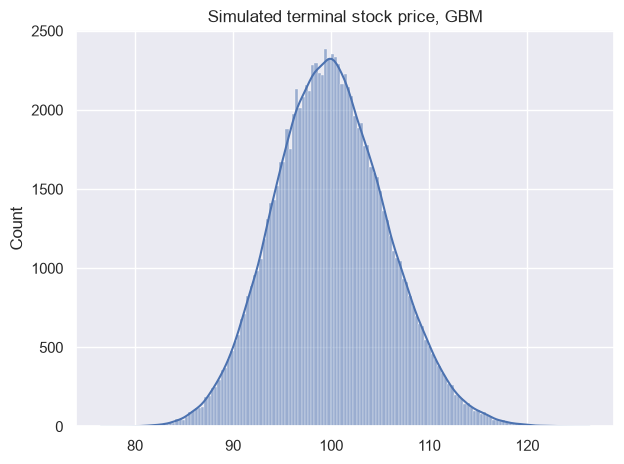

In [2]:
gbm = simulate_gbm(100000)
print(f'Simulated stock shape: {gbm['S'].shape}')
print(f'Simulated volatility shape: {gbm['V'].shape}')
print(f'If all stocks start with 100: {(gbm['S'][:, 0, 0] == 100).sum() == 100000}')
print(f'Std of final stock price: {(gbm['S'][:, -1, 0]).std()}')
print(f'Mean of final stock price: {(gbm['S'][:, -1, 0]).mean()}')
print(f'ATM call price: {(gbm['S'][:, -1, 0] - 100).clamp(min = 0).mean()}')
sns.set_theme()
sns.histplot(data = gbm['S'][:, -1, 0], kde = True)
plt.title("Simulated terminal stock price, GBM")
plt.tight_layout()
plt.show()

## Heston

*Simulate Heston paths; plot terminal spot, 10 sample stock paths, and the terminal variance-swap value.*

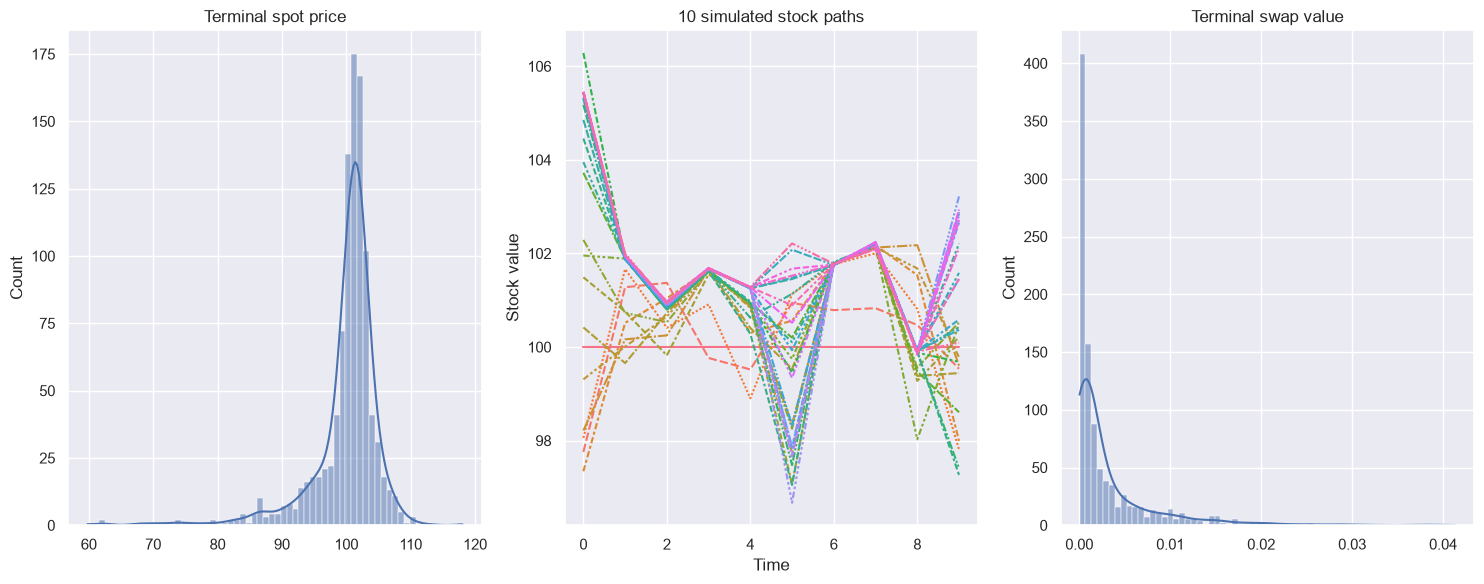

In [3]:
heston = simulate_heston(1000)
heston.keys()

# heston['S'].shape() = [1000, 31, 2] 
# 2 indicate the number of hedging instrument, i.e. one is stock and one is variance swap

heston['S'][:, :, 0] ## stocks

## terminal prices
sns.set_theme()
fig, ax = plt.subplots(1, 3, figsize = (15, 6))

sns.histplot(data = heston['S'][:, -1, 0].numpy(), ax = ax[0], kde = True)
ax[0].set_title("Terminal spot price")

sns.lineplot(data = heston['S'][:10, :, 0].numpy(), legend = False, ax = ax[1])
ax[1].set_title('10 simulated stock paths')
ax[1].set_ylabel('Stock value')
ax[1].set_xlabel('Time')

sns.histplot(data = heston['S'][:, -1, 1].numpy(), ax = ax[2], kde = True)
ax[2].set_title('Terminal swap value')
plt.tight_layout()
plt.show()

*Plot the terminal distribution of the instantaneous variance V and 50 sample variance paths.*

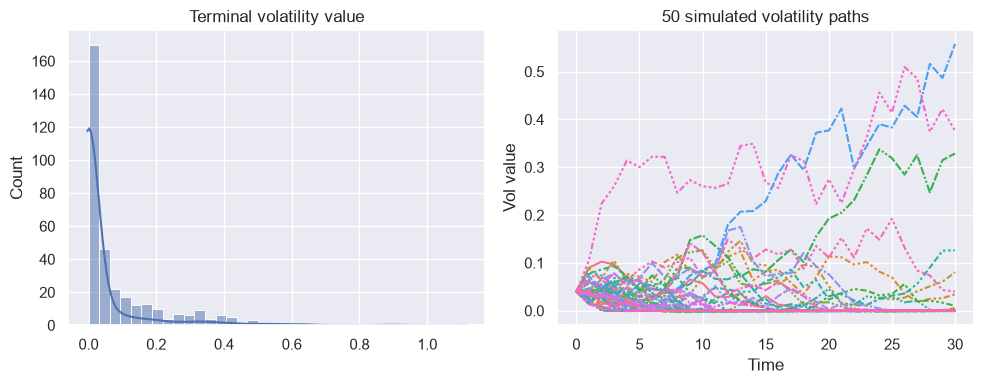

In [4]:
heston['V'] # the hidden volatility path

## terminal prices
sns.set_theme()
fig, ax = plt.subplots(1, 2, figsize = (10, 4))
sns.histplot(data = heston['V'][:, -1].numpy(), ax = ax[0], kde = True, binrange = (0, 0.5))
ax[0].set_title("Terminal volatility value")
sns.lineplot(data = heston['V'][:50, :].numpy().T, legend = False)
ax[1].set_title('50 simulated volatility paths')
ax[1].set_ylabel('Vol value')
ax[1].set_xlabel('Time')
plt.tight_layout()
plt.show()

*Shapes, terminal spot mean, and how many V values are negative (full-truncation Euler) and how negative.*

In [5]:
print(f"Shape of S: {heston['S'].shape}")
print(f"Shape of V: {heston['V'].shape}")
print(f"Mean of terminal stock price: {np.mean(heston['S'][:, -1, 0].numpy())}")

print(f"Count of negative volatility: {np.sum(heston['V'].numpy() < 0)}")
print(f"Count of vol < -0.002: {np.sum(heston['V'].numpy() < -0.002)}")

Shape of S: torch.Size([1000, 31, 2])
Shape of V: torch.Size([1000, 31])
Mean of terminal stock price: 99.92992401123047
Count of negative volatility: 13664
Count of vol < -0.002: 150


*Martingale check of the variance swap: mean of S2 at T vs at 0, in units of the standard error.*

In [6]:
out = simulate_heston(100000)
S2 = out["S"][:, :, 1]
B = S2.shape[0]
diff = S2[:, -1].mean() - S2[:, 0].mean()
se = S2[:, -1].std() / B ** 0.5
print(S2[:, 0].mean().item(), S2[:, -1].mean().item(), (diff / se).item())

0.0032876727636903524 0.0033206858206540346 1.9727160930633545


# Check on model.py

*Policy(3, 1): output shape, parameter count (4481), architecture printout.*

In [15]:
## testing the customized nn class
test_nn = Policy(d_in = 3, m_out = 1)
test_x = torch.randn((5, 3))
test_output = test_nn(test_x)
print(f'nn output shape: {test_output.shape}') ## shape of the output
print(f'nn parameter count: {sum(p.numel() for p in test_nn.parameters())}')
print(test_nn)



nn output shape: torch.Size([5, 1])
nn parameter count: 4481
Policy(
  (net): Sequential(
    (0): Linear(in_features=3, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


# Check on pricing.py

*BS price and delta at known values; delta and gamma vs central finite differences; batched shape.*

In [16]:
print(bs_price(100., 100., 30/365, 0.2))      # ≈ 2.287
print(bs_delta(105., 100., 10/365, 0.2))      # ≈ 0.932

S = torch.tensor(105., dtype=torch.float64); h = 0.01; tau = 10/365
print((bs_price(S+h, 100., tau, 0.2) - bs_price(S-h, 100., tau, 0.2)) / (2*h), bs_delta(S, 100., tau, 0.2))
print((bs_delta(S+h, 100., tau, 0.2) - bs_delta(S-h, 100., tau, 0.2)) / (2*h), bs_gamma(S, 100., tau, 0.2))

print(bs_delta(torch.linspace(90, 110, 5), 100., 10/365, 0.2).shape)   # (5,)

tensor(2.2872, dtype=torch.float64)
tensor(0.9319, dtype=torch.float64)
tensor(0.9319, dtype=torch.float64) tensor(0.9319, dtype=torch.float64)
tensor(0.0378, dtype=torch.float64) tensor(0.0378, dtype=torch.float64)
torch.Size([5])
